# FD001 remaining useful life: Linear Regression, Random Forest and XGBoost on the official test set

This notebook fits three models on the **training set** and predicts the **official NASA test set**.

| Step | What happens |
| --- | --- |
| Train | All 100 engines in `train_FD001.csv`, every row. RUL = the engine's last cycle minus the current cycle, uncapped (FR02, FR06) |
| Predict | The 100 truncated engines in `test_FD001.csv` |
| Score | Against the supplied `RUL_FD001.csv` labels (one true RUL per test engine, at its last observed cycle) |

**Models.** Linear Regression (scaled inputs), Random Forest and XGBoost. "LR" is taken to mean Linear Regression. Settings are the same first-pass settings as `02_model_rf_lstm.ipynb`, so nothing here was tuned against the test labels (FR03).

**Features.** The 12 sensors kept by the EDA, plus causal rolling mean and standard deviation over the latest 5 and 10 rows of each engine (60 columns, FR05). `engine_id` and `cycle` are never inputs.

**Headline scoring (FR09).** The official test question is one prediction per engine, made at its last observed cycle, compared with the supplied RUL. Error is predicted minus actual, so a positive error means the model is optimistic. A second table scores every test row (FR10), using truth = endpoint RUL + last cycle - current cycle.

This is an educational demo on simulated data, not a maintenance decision tool.

In [1]:
import json
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

SEED = 42
ROLL_WINDOWS = (5, 10)      # FR05: latest 5 and 10 observed rows
OVER_TOL = 20               # FR09: count predictions that overestimate by more than 20 cycles
SAVE_OUTPUTS = True

RF_PARAMS = dict(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED)
XGB_PARAMS = dict(n_estimators=400, learning_rate=0.05, max_depth=5, subsample=0.8,
                  colsample_bytree=0.8, random_state=SEED, n_jobs=-1)

random.seed(SEED)
np.random.seed(SEED)

INK, GRID = "#1F2933", "#E4E7EB"
COLORS = {"Linear Regression": "#8B939C", "Random Forest": "#2F6FB5", "XGBoost": "#C4660F"}
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 9,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#B8BEC6", "axes.labelcolor": INK, "text.color": INK,
    "xtick.color": INK, "ytick.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
})
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")


def find_project_root():
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "data" / "csv_preview" / "train_FD001.csv").exists():
            return p
    raise FileNotFoundError(
        "Could not find data/csv_preview/train_FD001.csv in this folder or any parent. "
        "Open the notebook from inside the project folder."
    )


ROOT = find_project_root()
print("Project root:", ROOT)

Project root: /sessions/rcw-01m9hvybxh73t3bfpjvc3rzb/mnt/RUL_prediction/TurbofanHPC_RUL_prediction


## 1. Load the data and build the labels

* **Training target (FR02).** RUL = the engine's final recorded cycle minus the current cycle, uncapped.
* **Test truth (FR02).** `RUL_FD001.csv` gives the RUL at each test engine's **last observed cycle**. That last cycle is *not* failure, so the label is not zero.
* The sensor list comes from the EDA's saved decisions (constant and uninformative columns already removed).

In [2]:
CSV_DIR = ROOT / "data" / "csv_preview"
train = pd.read_csv(CSV_DIR / "train_FD001.csv").sort_values(["engine_id", "cycle"]).reset_index(drop=True)
test = pd.read_csv(CSV_DIR / "test_FD001.csv").sort_values(["engine_id", "cycle"]).reset_index(drop=True)
rul = pd.read_csv(CSV_DIR / "RUL_FD001.csv")

eda = json.loads((ROOT / "artifacts" / "eda" / "eda_split_and_columns.json").read_text())
SENSORS = [c for c in eda["keep"] if c.startswith("sensor")]

# ---- basic checks (FR01) ---------------------------------------------------------------
assert list(train.columns) == list(test.columns), "train and test columns differ"
assert not train.isna().any().any() and not test.isna().any().any(), "missing values found"
assert not train.duplicated(["engine_id", "cycle"]).any() and not test.duplicated(["engine_id", "cycle"]).any()
assert all(c in train.columns for c in SENSORS)
assert len(rul) == test["engine_id"].nunique(), "RUL file must have one value per test engine"
assert set(rul["engine_id"]) == set(test["engine_id"]), "RUL engine ids do not match the test engines"

# ---- training target (FR02, FR06) ------------------------------------------------------
train["rul_cycles"] = train.groupby("engine_id")["cycle"].transform("max") - train["cycle"]
assert train.groupby("engine_id")["rul_cycles"].min().eq(0).all(), "every training engine must end at RUL 0"

# ---- test truth (FR02, FR10) -----------------------------------------------------------
last_cycle = test.groupby("engine_id")["cycle"].max().rename("last_cycle")
endpoint_truth = rul.set_index("engine_id")["remaining_cycles"].rename("rul_cycles")
test = test.merge(last_cycle, on="engine_id").merge(endpoint_truth, on="engine_id")
test["rul_cycles"] = test["rul_cycles"] + test["last_cycle"] - test["cycle"]      # trajectory truth

print(f"train {train.shape} ({train['engine_id'].nunique()} engines) | test {test.shape} ({test['engine_id'].nunique()} engines)")
print(f"{len(SENSORS)} sensors:", SENSORS)
print(f"Training RUL range {train['rul_cycles'].min()} to {train['rul_cycles'].max()} | "
      f"test endpoint RUL range {endpoint_truth.min()} to {endpoint_truth.max()}")

train (20631, 27) (100 engines) | test (13096, 28) (100 engines)
12 sensors: ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']
Training RUL range 0 to 361 | test endpoint RUL range 7 to 145


## 2. Features

The raw reading plus the rolling mean and standard deviation over the latest 5 and 10 rows of the **same engine** (FR05). Windows look backwards only, need at least one row (`min_periods=1`), and use `ddof=0`. The check below proves that cutting off the future leaves earlier feature values unchanged (AT03), which is what makes the test predictions fair: each test row is built from that engine's own past only.

In [3]:
def feature_names():
    names = list(SENSORS)
    for w in ROLL_WINDOWS:
        for s in SENSORS:
            names += [f"{s}_mean_{w}", f"{s}_std_{w}"]
    return names


def add_rolling_features(df):
    df = df.sort_values(["engine_id", "cycle"]).reset_index(drop=True)
    grouped = df.groupby("engine_id")[SENSORS]
    new_cols = {}
    for w in ROLL_WINDOWS:
        roll = grouped.rolling(window=w, min_periods=1)
        mean = roll.mean().reset_index(level=0, drop=True).sort_index()
        std = roll.std(ddof=0).reset_index(level=0, drop=True).sort_index()
        for s in SENSORS:
            new_cols[f"{s}_mean_{w}"] = mean[s]
            new_cols[f"{s}_std_{w}"] = std[s]
    return pd.concat([df, pd.DataFrame(new_cols)], axis=1)


FEATURES = feature_names()

# leakage check (AT03): chopping off later cycles must not change earlier features
one = test[test["engine_id"] == test["engine_id"].iloc[0]]
full, cut = add_rolling_features(one), add_rolling_features(one.iloc[:20])
assert np.allclose(full.iloc[:20][FEATURES].to_numpy(), cut[FEATURES].to_numpy()), "features use future rows"
print("Leakage check passed: features at cycle 20 are identical with or without later cycles.")

train_f = add_rolling_features(train)
test_f = add_rolling_features(test)

X_train, y_train = train_f[FEATURES], train_f["rul_cycles"]
X_test_all, y_test_all = test_f[FEATURES], test_f["rul_cycles"].to_numpy(float)

# one row per test engine: its last observed cycle (the official endpoint)
end_mask = test_f["cycle"] == test_f["last_cycle"]
test_end = test_f[end_mask].reset_index(drop=True)
X_test_end, y_test_end = test_end[FEATURES], test_end["rul_cycles"].to_numpy(float)
assert len(test_end) == 100 and test_end["engine_id"].is_unique
assert np.array_equal(test_end["rul_cycles"].to_numpy(), endpoint_truth.loc[test_end["engine_id"]].to_numpy())

print(f"{len(FEATURES)} features | training rows {len(X_train):,} | test rows {len(X_test_all):,} | test endpoints {len(X_test_end)}")

Leakage check passed: features at cycle 20 are identical with or without later cycles.


60 features | training rows 20,631 | test rows 13,096 | test endpoints 100


## 3. Fit the three models on the training set

Only training rows are used to fit anything, including the scaler inside the Linear Regression pipeline (FR04). The test set is not seen until section 4.

In [4]:
models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Random Forest": RandomForestRegressor(**RF_PARAMS),
    "XGBoost": XGBRegressor(**XGB_PARAMS),
}
for name, m in models.items():
    t0 = time.time()
    m.fit(X_train, y_train)
    print(f"{name:<18} fitted on {len(X_train):,} rows in {time.time() - t0:4.1f} s")

Linear Regression  fitted on 20,631 rows in  0.0 s


Random Forest      fitted on 20,631 rows in 44.6 s


XGBoost            fitted on 20,631 rows in  0.6 s


## 4. Predict the test set

Predictions are clipped at 0 because remaining life cannot be negative (FR06). Each model predicts every test row; the headline table keeps only the last row of each engine.

In [5]:
def clip_nonneg(p):
    return np.clip(np.asarray(p, float), 0, None)


pred_all = {name: clip_nonneg(m.predict(X_test_all)) for name, m in models.items()}
pred_end = {name: p[end_mask.to_numpy()] for name, p in pred_all.items()}
print("Predicted", len(X_test_all), "test rows with each model;", len(X_test_end), "are official endpoints.")

Predicted 13096 test rows with each model; 100 are official endpoints.


## 5. Results: one prediction per test engine (headline)

| Measure | Meaning |
| --- | --- |
| MAE | Average size of the error, in cycles |
| RMSE | Like MAE but penalises big misses more |
| R2 | Share of the variation in the 100 true endpoint RULs that the model explains. 0 is no better than predicting their average, below 0 is worse |
| mean signed error | Predicted minus actual, averaged. Above 0 means optimistic |
| over by >20 (%) | Share of engines where the model overestimates by more than 20 cycles, the risky direction |
| NASA score | The C-MAPSS challenge score: late (optimistic) predictions are punished harder than early ones. Lower is better |

In [6]:
def nasa_score(err):
    # C-MAPSS scoring function; err = predicted - actual
    err = np.asarray(err, float)
    return float(np.sum(np.where(err < 0, np.exp(-err / 13) - 1, np.exp(err / 10) - 1)))


def report(y, pred, name, engine_ids=None):
    y = np.asarray(y, float)
    err = np.asarray(pred, float) - y
    out = {
        "model": name, "n": len(y),
        "MAE": np.mean(np.abs(err)), "RMSE": np.sqrt(np.mean(err ** 2)), "R2": r2_score(y, pred),
        "mean signed error": err.mean(), f"over by >{OVER_TOL} (%)": 100 * np.mean(err > OVER_TOL),
    }
    if engine_ids is not None:       # FR10: engine-averaged errors so long-lived engines do not dominate
        per = (pd.DataFrame({"e": engine_ids, "abs": np.abs(err), "sq": err ** 2}).groupby("e")
               .agg(mae=("abs", "mean"), mse=("sq", "mean")))
        out["engine-avg MAE"], out["engine-avg RMSE"] = per["mae"].mean(), np.sqrt(per["mse"]).mean()
    return out


endpoint_table = pd.DataFrame(
    [{**report(y_test_end, pred_end[n], n), "NASA score": nasa_score(pred_end[n] - y_test_end)} for n in models]
).set_index("model")
print(f"OFFICIAL TEST SET: {len(test_end)} engines, one endpoint each. Trained on {train['engine_id'].nunique()} training engines.\n")
display(endpoint_table)
print(f"\nLowest MAE: {endpoint_table['MAE'].idxmin()} | lowest RMSE: {endpoint_table['RMSE'].idxmin()} "
      f"| highest R2: {endpoint_table['R2'].idxmax()}")

OFFICIAL TEST SET: 100 engines, one endpoint each. Trained on 100 training engines.



,n,MAE,RMSE,R2,mean signed error,over by >20 (%),NASA score
model,,,,,,,
Linear Regression,100,27.26,33.42,0.35,22.13,53.00,"11,644.15"
Random Forest,100,26.05,35.92,0.25,20.55,39.00,"42,236.17"
XGBoost,100,25.30,34.61,0.31,18.44,41.00,"32,997.25"



Lowest MAE: XGBoost | lowest RMSE: Linear Regression | highest R2: Linear Regression


## 6. Results: every test row (trajectory view)

This scores all test rows, not only the last one. Earlier rows are further from failure, so errors here mix easy and hard situations, and rows from long-lived engines count more. The engine-averaged columns correct for that (FR10). Treat this as a secondary view; the endpoint table above is the headline.

In [7]:
traj_table = pd.DataFrame(
    [report(y_test_all, pred_all[n], n, engine_ids=test_f["engine_id"].to_numpy()) for n in models]
).set_index("model")
print(f"OFFICIAL TEST SET: all {len(test_f):,} rows from {test_f['engine_id'].nunique()} engines.\n")
display(traj_table)

OFFICIAL TEST SET: all 13,096 rows from 100 engines.



,n,MAE,RMSE,R2,mean signed error,over by >20 (%),engine-avg MAE,engine-avg RMSE
model,,,,,,,,
Linear Regression,13096,35.82,47.02,0.36,-5.01,31.60,32.52,38.23
Random Forest,13096,36.75,48.30,0.33,-4.53,30.92,33.78,40.04
XGBoost,13096,36.69,48.33,0.33,-4.87,30.89,33.86,40.22


## 7. Plots

Left: predicted against actual RUL at each engine's last cycle (the dashed line is a perfect prediction; points above it are optimistic). Right: the error for each engine, sorted, so the few large misses are easy to see.

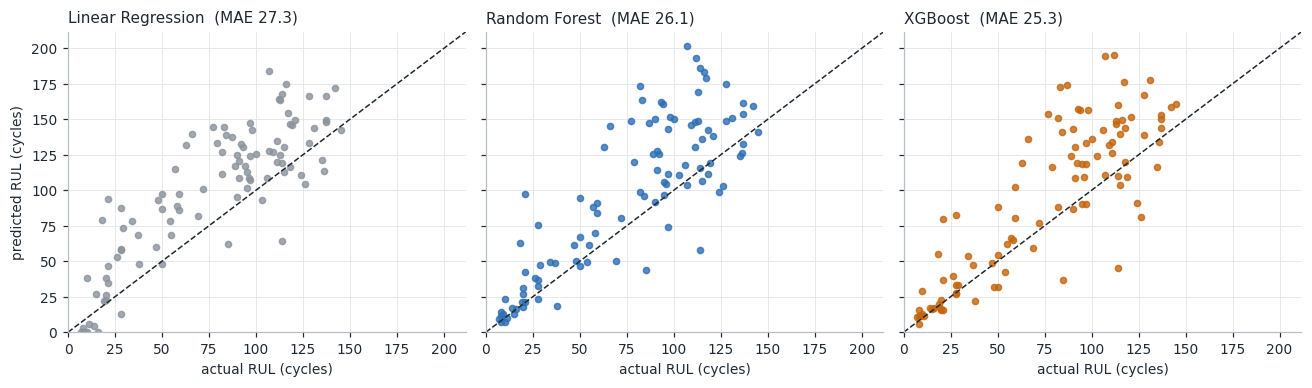

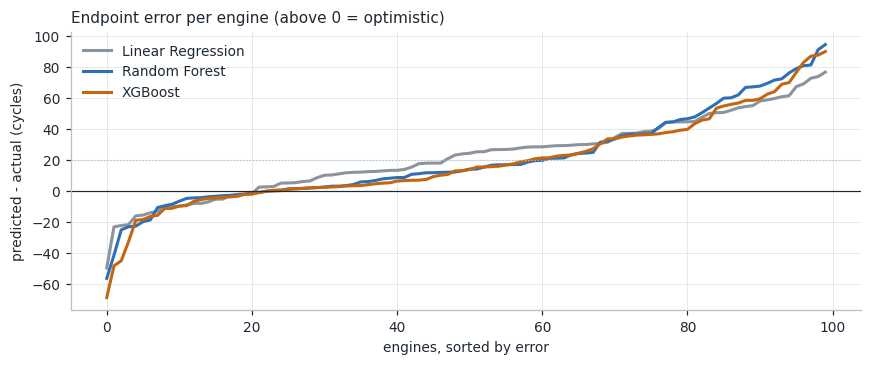

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharex=True, sharey=True)
top = max(y_test_end.max(), *(p.max() for p in pred_end.values())) * 1.05
for ax, (name, p) in zip(axes, pred_end.items()):
    ax.scatter(y_test_end, p, s=16, color=COLORS[name], alpha=0.8)
    ax.plot([0, top], [0, top], ls="--", color=INK, lw=1)
    ax.set_title(f"{name}  (MAE {np.mean(np.abs(p - y_test_end)):.1f})", loc="left", fontsize=10)
    ax.set_xlabel("actual RUL (cycles)")
axes[0].set_ylabel("predicted RUL (cycles)")
ax.set_xlim(0, top); ax.set_ylim(0, top)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 3.4))
for name, p in pred_end.items():
    ax.plot(np.sort(p - y_test_end), color=COLORS[name], lw=2, label=name)
ax.axhline(0, color=INK, lw=0.8)
ax.axhline(OVER_TOL, color="#B8BEC6", lw=0.8, ls=":")
ax.set_xlabel("engines, sorted by error")
ax.set_ylabel("predicted - actual (cycles)")
ax.set_title("Endpoint error per engine (above 0 = optimistic)", loc="left", fontsize=10)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 8. Per-engine predictions and saved outputs

The table keeps the dataset split in the key (`dataset_id`, FR/UI07) so test engine 1 is never confused with training engine 1. Outputs go to `artifacts/model/`.

In [9]:
per_engine = pd.DataFrame({
    "dataset_id": "FD001_test", "engine_id": test_end["engine_id"], "observed_cycle": test_end["last_cycle"],
    "actual_rul": y_test_end,
    **{f"{n} predicted": pred_end[n] for n in models},
    **{f"{n} error": pred_end[n] - y_test_end for n in models},
})
display(per_engine.head(10))

worst = per_engine.assign(worst=per_engine[[f"{n} error" for n in models]].abs().max(axis=1)).nlargest(5, "worst")
print("Five engines where the largest model error is biggest:")
display(worst.drop(columns="worst"))

if SAVE_OUTPUTS:
    out_dir = ROOT / "artifacts" / "model"
    out_dir.mkdir(parents=True, exist_ok=True)
    per_engine.to_csv(out_dir / "test_endpoint_predictions_lr_rf_xgb.csv", index=False)
    endpoint_table.to_csv(out_dir / "test_metrics_endpoint_lr_rf_xgb.csv")
    traj_table.to_csv(out_dir / "test_metrics_trajectory_lr_rf_xgb.csv")
    print("\nSaved to artifacts/model/: test_endpoint_predictions_lr_rf_xgb.csv, test_metrics_endpoint_lr_rf_xgb.csv, test_metrics_trajectory_lr_rf_xgb.csv")

,dataset_id,engine_id,observed_cycle,actual_rul,Linear Regression predicted,Random Forest predicted,XGBoost predicted,Linear Regression error,Random Forest error,XGBoost error
0,FD001_test,1,31,112.00,164.09,193.25,194.97,52.09,81.25,82.97
1,FD001_test,2,49,98.00,142.60,151.48,156.47,44.60,53.48,58.47
2,FD001_test,3,126,69.00,81.51,50.35,59.60,12.51,-18.65,-9.40
3,FD001_test,4,106,82.00,111.24,98.90,88.43,29.24,16.90,6.43
4,FD001_test,5,98,91.00,108.59,127.61,130.76,17.59,36.61,39.76
5,FD001_test,6,105,93.00,130.14,162.45,157.12,37.14,69.45,64.12
6,FD001_test,7,160,91.00,120.53,114.37,108.47,29.53,23.37,17.47
7,FD001_test,8,166,95.00,113.02,105.77,118.21,18.02,10.77,23.21
8,FD001_test,9,55,111.00,119.63,148.00,134.02,8.63,37.00,23.02
9,FD001_test,10,192,96.00,108.62,104.67,108.99,12.62,8.67,12.99


Five engines where the largest model error is biggest:


,dataset_id,engine_id,observed_cycle,actual_rul,Linear Regression predicted,Random Forest predicted,XGBoost predicted,Linear Regression error,Random Forest error,XGBoost error
77,FD001_test,78,72,107.00,183.67,201.46,194.64,76.67,94.46,87.64
96,FD001_test,97,134,82.00,126.60,173.10,150.87,44.60,91.10,68.87
14,FD001_test,15,76,83.00,144.44,163.81,172.96,61.44,80.81,89.96
18,FD001_test,19,135,87.00,137.65,147.09,173.94,50.65,60.09,86.94
0,FD001_test,1,31,112.00,164.09,193.25,194.97,52.09,81.25,82.97



Saved to artifacts/model/: test_endpoint_predictions_lr_rf_xgb.csv, test_metrics_endpoint_lr_rf_xgb.csv, test_metrics_trajectory_lr_rf_xgb.csv


## Notes and limits

* **Single test run.** The official test labels were opened once, for this notebook, using settings fixed beforehand. If you tune any model afterwards, do it on validation engines and not on these scores, or the test result stops being an honest estimate (FR03).
* **Only 100 test engines.** Endpoint metrics rest on 100 predictions, so small differences between models are within noise.
* **Uncapped target.** Models learn the full life, including the long, flat early phase, so the large early-life RULs are the hardest to predict. A capped target is a separate experiment and would have to be reported separately (FR06).
* **Point estimates only.** No uncertainty band is shown, and cycles cannot be converted to calendar time.
* **Simulated data, FD001 only.** One operating condition and one fault mode. These results say nothing about real aircraft engines.